In [7]:

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.base import clone

from xgboost import XGBClassifier

# Load raw data
df = pd.read_csv("../data/raw/Telco-Customer-Churn.csv")

# Clean TotalCharges
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].astype(str).str.strip(),
    errors="coerce"
)
df.loc[df["TotalCharges"].isna(), "TotalCharges"] = 0

# Create features and target
X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"].map({"No": 0, "Yes": 1})

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Identify feature types
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

# Build preprocessing pipeline
numerical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Setup complete!")
print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)
print("Preprocessor ready:", preprocessor is not None)


Setup complete!
Training set: (5634, 19)
Testing set: (1409, 19)
Preprocessor ready: True


In [8]:

from sklearn.metrics import (
    make_scorer,
    precision_score,
    recall_score,
    f1_score
)

# Define the models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=1
    ),
    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    )
}

# Cross-validation setup
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
    "recall": "recall",
    "f1": "f1"
}

results = []

for name, classifier in models.items():
    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", classifier)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    results.append({
        "Model": name,
        "ROC-AUC": scores["test_roc_auc"].mean(),
        "PR-AUC (AP)": scores["test_average_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-score": scores["test_f1"].mean()
    })

results_df = pd.DataFrame(results).sort_values(
    "PR-AUC (AP)",
    ascending=False
)

display(results_df.round(4))


,Model,ROC-AUC,PR-AUC (AP),Recall,F1-score
2,XGBoost,0.8495,0.6710,0.5258,0.5882
0,Logistic Regression,0.8462,0.6617,0.5431,0.5923
1,Random Forest,0.8356,0.6366,0.5023,0.5693


In [9]:

from sklearn.model_selection import train_test_split
from sklearn.base import clone

# Split training data into model-training and validation sets
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# Build the XGBoost pipeline
xgb_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", XGBClassifier(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    ))
])

# Fit using only the fitting subset
xgb_model.fit(X_fit, y_fit)

# Get churn probabilities on validation data
val_probabilities = xgb_model.predict_proba(X_val)[:, 1]

print("Validation samples:", len(X_val))
print("Validation churn rate:", round(y_val.mean(), 4))
print("Predictions generated successfully!")


Validation samples: 1127
Validation churn rate: 0.2653
Predictions generated successfully!


In [10]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import pandas as pd

thresholds = [0.30, 0.35, 0.40, 0.45, 0.50]

threshold_results = []

for threshold in thresholds:
    # Predict churn when probability meets the threshold
    y_val_pred = (
        val_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, y_val_pred, labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, y_val_pred, zero_division=0),
        "Recall": recall_score(y_val, y_val_pred, zero_division=0),
        "F1-score": f1_score(y_val, y_val_pred, zero_division=0),
        "True Positives": tp,
        "False Positives": fp,
        "False Negatives": fn,
        "True Negatives": tn
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))


,Threshold,Precision,Recall,F1-score,True Positives,False Positives,False Negatives,True Negatives
0,0.30,0.5481,0.7625,0.6378,228,188,71,640
1,0.35,0.5806,0.7224,0.6438,216,156,83,672
2,0.40,0.6391,0.6455,0.6423,193,109,106,719
3,0.45,0.6717,0.5953,0.6312,178,87,121,741
4,0.50,0.7177,0.5017,0.5906,150,59,149,769


Threshold: 0.35
Accuracy: 0.7729
Precision: 0.5556
Recall: 0.7219
F1-score: 0.6279
ROC-AUC: 0.8472
PR-AUC (AP): 0.668

Classification report:
              precision    recall  f1-score   support

    No Churn       0.89      0.79      0.84      1035
       Churn       0.56      0.72      0.63       374

    accuracy                           0.77      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.77      0.78      1409



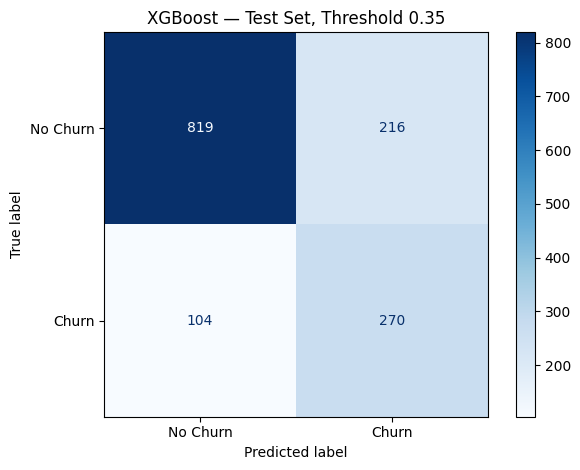

In [11]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Retrain on the complete training set
xgb_model.fit(X_train, y_train)

# Predict churn probabilities on the untouched test set
test_probabilities = xgb_model.predict_proba(X_test)[:, 1]

# Apply the threshold selected on validation data
chosen_threshold = 0.35
y_test_pred = (
    test_probabilities >= chosen_threshold
).astype(int)

# Evaluate
print("Threshold:", chosen_threshold)
print("Accuracy:", round(accuracy_score(y_test, y_test_pred), 4))
print("Precision:", round(precision_score(y_test, y_test_pred), 4))
print("Recall:", round(recall_score(y_test, y_test_pred), 4))
print("F1-score:", round(f1_score(y_test, y_test_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, test_probabilities), 4))
print("PR-AUC (AP):", round(average_precision_score(
    y_test, test_probabilities
), 4))

print("\nClassification report:")
print(classification_report(
    y_test, y_test_pred, target_names=["No Churn", "Churn"]
))

# Plot the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=["No Churn", "Churn"],
    cmap="Blues"
)
plt.title("XGBoost — Test Set, Threshold 0.35")
plt.tight_layout()
plt.show()


c:\python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


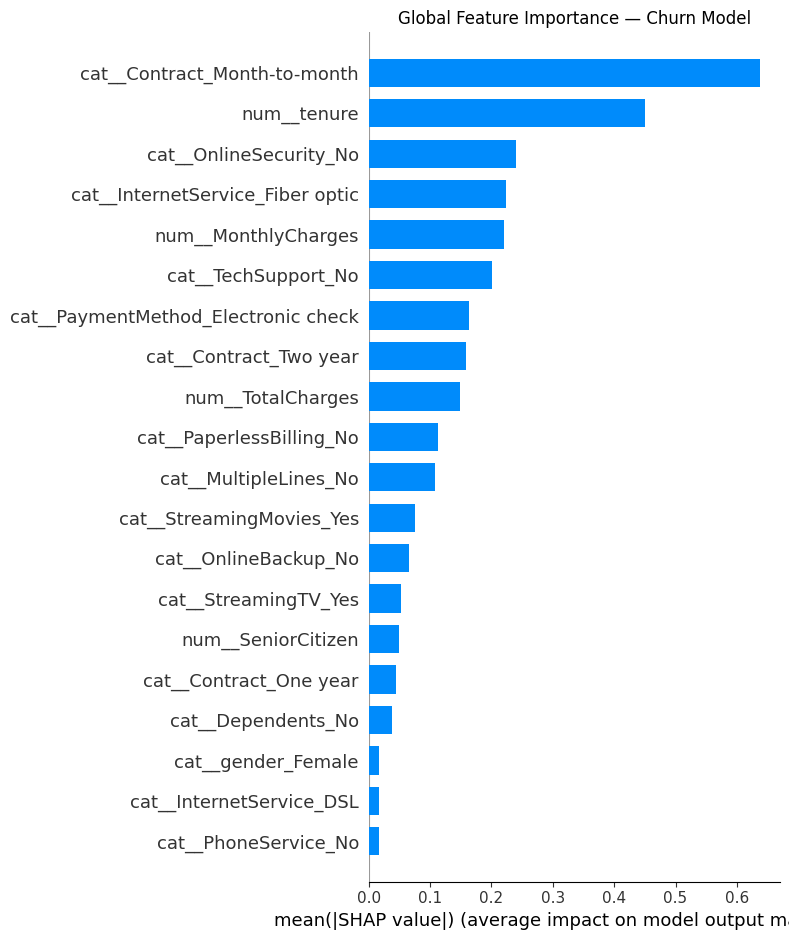

In [12]:

import shap
import pandas as pd
import matplotlib.pyplot as plt

# Transform test data using the fitted preprocessing pipeline
fitted_preprocessor = xgb_model.named_steps["preprocessor"]
fitted_classifier = xgb_model.named_steps["classifier"]

X_test_transformed = fitted_preprocessor.transform(X_test)

# Recover feature names after one-hot encoding
feature_names = fitted_preprocessor.get_feature_names_out()

# Use a manageable sample for explainability
X_shap = X_test_transformed[:200]

# Create SHAP explainer for XGBoost
explainer = shap.TreeExplainer(fitted_classifier)
shap_values = explainer.shap_values(X_shap)

# Global feature importance
shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=feature_names,
    plot_type="bar",
    show=False
)

plt.title("Global Feature Importance — Churn Model")
plt.tight_layout()
plt.show()


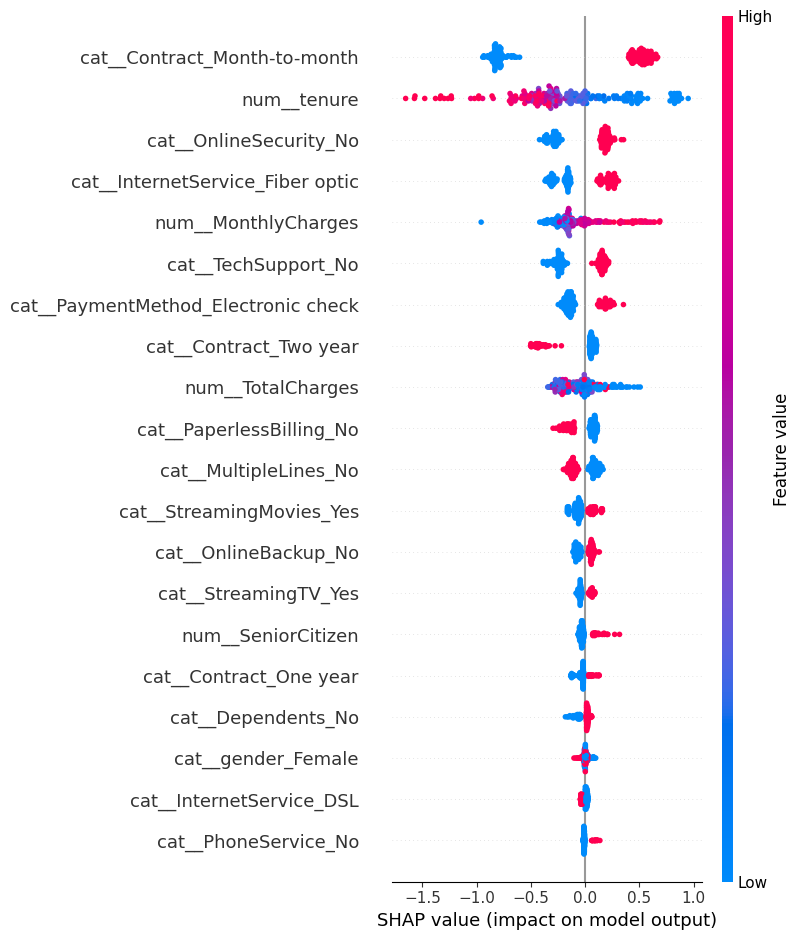

In [13]:
shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=feature_names,
    show=True
)

In [14]:

from pathlib import Path
import joblib
import json

# Create the models directory if it doesn't exist
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save the complete pipeline
model_path = MODEL_DIR / "churn_model.joblib"
joblib.dump(xgb_model, model_path)

# Save the selected decision threshold separately
threshold_path = MODEL_DIR / "threshold.json"

with open(threshold_path, "w") as f:
    json.dump({"threshold": 0.35}, f, indent=4)

print("Model saved:", model_path.resolve())
print("Threshold saved:", threshold_path.resolve())


Model saved: D:\customer-churn-prediction\models\churn_model.joblib
Threshold saved: D:\customer-churn-prediction\models\threshold.json
